<a href="https://colab.research.google.com/github/Oryx-00/titanic-machine-learning/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
from sklearn.datasets import fetch_openml

titanic_df = fetch_openml("titanic", version=1, as_frame=True)

Importing the Titanic dataset as a Pandas DataFrame.

In [28]:
titanic=titanic_df.frame
titanic

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,NaN,C,NaN,328.0,NaN
1305,3,0,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,NaN,C,NaN,NaN,NaN


Analyzing the overall structure of the dataset.

In [29]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   object  
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   object  
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    object  
 10  embarked   1307 non-null   category
 11  boat       486 non-null    object  
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    object  
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB


Analyzing the different variables to check their types, identify missing data, and determine if some should be removed. We observe that:

* The body and boat variables must absolutely be removed because they directly indicate whether the person survived (this causes data leakage).

* The cabin variable has a huge number of missing values, so it is better to drop it entirely.

* The home.dest and ticket variables are not useful and must be removed to avoid overfitting during training. If we keep them, the algorithm might create spurious correlations with survival, preventing it from generalizing well to new data.

In [30]:
titanic = titanic.drop(["body", "boat", "cabin", "home.dest", "ticket"], axis=1)

In [31]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   pclass    1309 non-null   int64   
 1   survived  1309 non-null   category
 2   name      1309 non-null   object  
 3   sex       1309 non-null   category
 4   age       1046 non-null   float64 
 5   sibsp     1309 non-null   int64   
 6   parch     1309 non-null   int64   
 7   fare      1308 non-null   float64 
 8   embarked  1307 non-null   category
dtypes: category(3), float64(2), int64(3), object(1)
memory usage: 65.7+ KB


In [32]:
titanic.describe()

,pclass,age,sibsp,parch,fare
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000
mean,2.294882,29.881135,0.498854,0.385027,33.295479
std,0.837836,14.413500,1.041658,0.865560,51.758668
min,1.000000,0.166700,0.000000,0.000000,0.000000
25%,2.000000,21.000000,0.000000,0.000000,7.895800
50%,3.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,39.000000,1.000000,0.000000,31.275000
max,3.000000,80.000000,8.000000,9.000000,512.329200


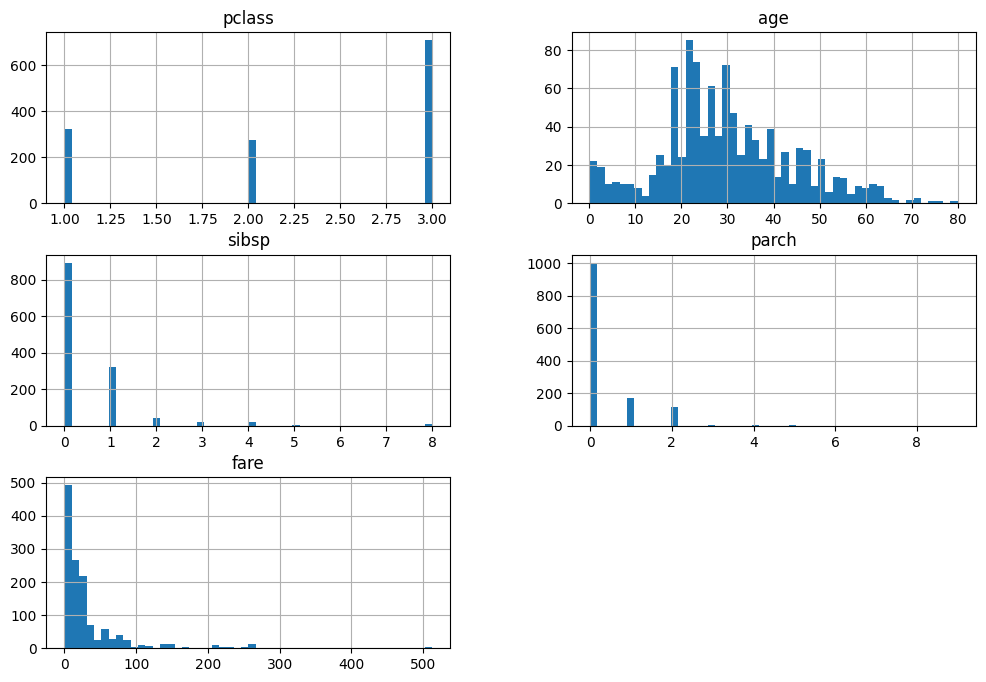

In [33]:
import matplotlib.pyplot as plt
titanic.hist(bins=50, figsize=(12,8))
plt.show()

We plot the distributions of the different variables to analyze if there are truncated values, outliers, or skewed distributions that would require data cleaning.

In [34]:
from sklearn.model_selection import train_test_split

X = titanic.drop(["survived"], axis=1)
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=titanic["survived"], random_state=42)

We split our data using stratified sampling based on the survived variable. The advantage of this type of sampling over a simple random split is that it ensures our algorithm encounters the correct proportion of people who survived. Since we don't have a large number of survivors, a purely random split might result in a training set with very few of them, making it difficult for the algorithm to learn the patterns of survival.

In [35]:
titanic["survived"] = titanic["survived"].astype(int)

We convert the values of the survived variable into integers, which is required to compute the correlation matrix.

In [36]:
corr_matrix = titanic.corr(numeric_only=True)
corr_matrix["survived"].sort_values(ascending=False)

,survived
survived,1.000000
fare,0.244265
parch,0.082660
sibsp,-0.027825
age,-0.055513
pclass,-0.312469


We compute the correlation matrix with respect to the survived variable using only the numerical features, and we sort the correlations. Note that variables with negative correlations (like pclass at the bottom) can still be strongly correlated with survival, just in an inverse manner.

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


def compute_family_size(X):
  return X[:, [0]] + X[:, [1]] + 1

def family_name(function_transformer, feature_names_in_):
  return ["family"]

def family_pipeline():
  return make_pipeline(
      SimpleImputer(strategy="median"),
      FunctionTransformer(compute_family_size, feature_names_out=family_name),
      StandardScaler())

num_attribs = ["pclass", "age", "fare"]
cat_attribs = ["sex", "embarked"]
family_attribs = ["sibsp", "parch"]


cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))
])
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

preprocessing = ColumnTransformer([
    ("family", family_pipeline(), family_attribs),
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs)
])

X_train_prepared = preprocessing.fit_transform(X_train)
X_test_prepared = preprocessing.transform(X_test)

We create a pipeline to automate our data processing. In this pipeline, we:

* Create a custom function to add the sibsp and parch variables together to create a new family size feature. This specific pipeline also imputes missing values using the median and scales the features.

* For non-numerical variables, we impute missing values with the most frequent value and use an encoder (OneHotEncoder) to transform them into a numerical format.

* For numerical variables, we impute missing values with the median and standardize our features.


In [38]:
import pandas as pd

df_titanic_prepared = pd.DataFrame(
    X_train_prepared, columns=preprocessing.get_feature_names_out(),
    index=y_train.index)

df_titanic_prepared["survived"] = y_train.astype(int)

corr_matrix = df_titanic_prepared.corr()
corr_matrix["survived"].sort_values(ascending=False)

,survived
survived,1.000000
num__fare,0.247448
cat__embarked_C,0.205914
family__family,0.046585
cat__embarked_Q,-0.035315
num__age,-0.060929
cat__embarked_S,-0.157836
num__pclass,-0.299562
cat__sex_male,-0.517007


We create a Pandas DataFrame with our new processed variables and compute a new correlation matrix. We can see that the individual's sex is the variable most correlated with survival. Therefore, encoding it was a highly effective step.

In [39]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_prepared, y_train)
cross_val_score(knn_clf, X_train_prepared, y_train, cv=5)

array([0.7952381 , 0.73333333, 0.784689  , 0.77990431, 0.75119617])

We test our first algorithm, K-Nearest Neighbors (KNN), using cross-validation. The scores are quite good even without hyperparameter tuning, as an accuracy between 79% and 82% is considered a solid baseline for this dataset.

In [40]:
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train_prepared, y_train)
cross_val_score(rf_clf, X_train_prepared, y_train, cv=5)

array([0.8       , 0.76190476, 0.77033493, 0.78947368, 0.71291866])

Our second algorithm is Random Forest. The cross-validation scores show a higher standard deviation than KNN, making it a less stable choice in this initial run.

In [41]:
from sklearn.svm import SVC

svm_clf = SVC(kernel="rbf", random_state=42)
svm_clf.fit(X_train_prepared, y_train)
cross_val_score(svm_clf, X_train_prepared, y_train, cv=5)

array([0.82380952, 0.77619048, 0.81339713, 0.80861244, 0.77990431])

The Support Vector Machine (SVC) algorithm achieves the best and most consistent scores, so we decide to keep it as our main candidate. However, we will try to find the optimal hyperparameters for all three algorithms before making a final conclusion.

In [42]:
from sklearn.model_selection import RandomizedSearchCV

param_dist={
  "n_neighbors": list(range(1, 50, 2)),
  "weights":  ['uniform', 'distance']
}

random_search = RandomizedSearchCV(
    estimator=knn_clf,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_prepared, y_train)

RandomizedSearchCV(cv=3, estimator=KNeighborsClassifier(), n_iter=20, n_jobs=-1,
                   param_distributions={'n_neighbors': [1, 3, 5, 7, 9, 11, 13,
                                                        15, 17, 19, 21, 23, 25,
                                                        27, 29, 31, 33, 35, 37,
                                                        39, 41, 43, 45, 47,
                                                        49],
                                        'weights': ['uniform', 'distance']},
                   random_state=42, scoring='accuracy')

We optimize our KNN algorithm using a randomized search (RandomizedSearchCV), which is the best strategy when the search space is large. Once we know where the algorithm converges best, we could theoretically use a GridSearchCV for a more exhaustive search. Here, we optimize the number of neighbors (k) and the distance metric (weights).

In [43]:
import pandas as pd

cv_res=pd.DataFrame(random_search.cv_results_)
cv_res=cv_res.sort_values(by="mean_test_score", ascending=False)
cv_res.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_weights,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
13,0.003838,0.000463,0.009357,0.000113,uniform,9,"{'weights': 'uniform', 'n_neighbors': 9}",0.785100,0.793696,0.762178,0.780325,0.013303,1
15,0.003336,0.000034,0.009104,0.000042,uniform,7,"{'weights': 'uniform', 'n_neighbors': 7}",0.767908,0.785100,0.773639,0.775549,0.007147,2
11,0.003363,0.000059,0.009962,0.001556,uniform,5,"{'weights': 'uniform', 'n_neighbors': 5}",0.765043,0.787966,0.762178,0.771729,0.011541,3
6,0.004100,0.000522,0.012439,0.000094,uniform,27,"{'weights': 'uniform', 'n_neighbors': 27}",0.767908,0.773639,0.767908,0.769819,0.002701,4
10,0.003928,0.000739,0.010051,0.000273,uniform,13,"{'weights': 'uniform', 'n_neighbors': 13}",0.744986,0.782235,0.776504,0.767908,0.016377,5


The algorithm seems to have hit a ceiling at around 80% accuracy, with the best parameters being 9 neighbors and uniform weights. We prefer to focus our efforts on tuning the other algorithms rather than running a deeper grid search.

In [44]:
param_dist={
  "n_estimators": list(range(200, 500)),
  "max_depth": list(range(5, 16)),
  "min_samples_split":  list(range(10,20)),
  "max_features": ['sqrt']
}

random_search = RandomizedSearchCV(
    estimator=rf_clf,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_prepared, y_train)

RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'max_depth': [5, 6, 7, 8, 9, 10, 11, 12,
                                                      13, 14, 15],
                                        'max_features': ['sqrt'],
                                        'min_samples_split': [10, 11, 12, 13,
                                                              14, 15, 16, 17,
                                                              18, 19],
                                        'n_estimators': [200, 201, 202, 203,
                                                         204, 205, 206, 207,
                                                         208, 209, 210, 211,
                                                         212, 213, 214, 215,
                                                         216, 217, 218, 219,
                                                         220, 221, 222, 223,
                                                         224, 225, 226, 227,
                                                         228, 229, ...]},
                   random_state=42, scoring='accuracy')

We test the Random Forest algorithm using RandomizedSearchCV.

In [45]:
import pandas as pd

df = pd.DataFrame(random_search.cv_results_).sort_values(by="mean_test_score", ascending=False)
df.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_estimators,param_min_samples_split,param_max_features,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
13,1.202592,0.004436,0.074090,0.001415,393,15,sqrt,14,"{'n_estimators': 393, 'min_samples_split': 15,...",0.802292,0.799427,0.790831,0.797517,0.004870,1
5,0.818598,0.023339,0.055808,0.008083,262,13,sqrt,12,"{'n_estimators': 262, 'min_samples_split': 13,...",0.796562,0.805158,0.787966,0.796562,0.007019,2
0,1.324726,0.117443,0.093432,0.023502,395,12,sqrt,10,"{'n_estimators': 395, 'min_samples_split': 12,...",0.799427,0.793696,0.790831,0.794651,0.003574,3
14,0.893087,0.002688,0.054465,0.001399,296,11,sqrt,7,"{'n_estimators': 296, 'min_samples_split': 11,...",0.793696,0.805158,0.785100,0.794651,0.008216,3
17,0.780458,0.010632,0.047054,0.000912,242,13,sqrt,11,"{'n_estimators': 242, 'min_samples_split': 13,...",0.799427,0.793696,0.790831,0.794651,0.003574,3


The resulting scores are roughly equivalent to those obtained with KNN.

In [46]:
from scipy.stats import loguniform

param_dist={
  "C": loguniform(20, 40),
  "gamma": ['scale', 'auto'] + list(loguniform(0.025, 0.04).rvs(size=100)),
  "kernel":  ['rbf']
}

random_search = RandomizedSearchCV(
    estimator=svm_clf,
    param_distributions=param_dist,
    n_iter=40,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_prepared, y_train)

RandomizedSearchCV(cv=5, estimator=SVC(random_state=42), n_iter=40, n_jobs=-1,
                   param_distributions={'C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7d4cac253950>,
                                        'gamma': ['scale', 'auto',
                                                  np.float64(0.039814227734195025),
                                                  np.float64(0.035114187703425344),
                                                  np.float64(0.03061812260001898),
                                                  np.float64(0.025811745154839714),
                                                  np.float64(0.026...
                                                  np.float64(0.027863608220375972),
                                                  np.float64(0.03146335962443264),
                                                  np.float64(0.037137783656682334),
                                                  np.float64(0.03920049744013988),
                                                  np.float64(0.026209731390189357),
                                                  np.float64(0.027863454006244785),
                                                  np.float64(0.03298000360967025),
                                                  np.float64(0.03485088595675734),
                                                  np.float64(0.025995474849653723), ...],
                                        'kernel': ['rbf']},
                   random_state=42, scoring='accuracy')

We do the same with our best candidate, the SVM. We use loguniform because it allows us to draw random numbers evenly across multiple orders of magnitude (powers of 10), which is ideal for tuning parameters like C and gamma.

In [47]:
import pandas as pd

df_cv = pd.DataFrame(random_search.cv_results_)
df_cv=df_cv.sort_values(by="mean_test_score", ascending=False)
df_cv.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_gamma,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
21,0.053689,0.004112,0.011568,0.000278,39.058378,0.039164,rbf,"{'C': 39.058377844131066, 'gamma': 0.039164093...",0.823810,0.776190,0.813397,0.813397,0.789474,0.803254,0.017610,1
17,0.059957,0.009775,0.011588,0.000214,39.537753,0.039814,rbf,"{'C': 39.53775309057417, 'gamma': 0.0398142277...",0.823810,0.776190,0.813397,0.808612,0.789474,0.802297,0.017157,2
24,0.073653,0.021997,0.016818,0.005620,21.765426,0.038113,rbf,"{'C': 21.765425661242194, 'gamma': 0.038113037...",0.828571,0.780952,0.803828,0.813397,0.784689,0.802288,0.017785,3
11,0.043469,0.001344,0.011897,0.000251,20.098200,0.02759,rbf,"{'C': 20.0982000859767, 'gamma': 0.02758972143...",0.838095,0.785714,0.799043,0.813397,0.775120,0.802274,0.022040,4
20,0.043504,0.001160,0.012081,0.001216,20.184739,0.02759,rbf,"{'C': 20.184739406818185, 'gamma': 0.027589721...",0.838095,0.790476,0.799043,0.808612,0.775120,0.802269,0.021025,5


We get excellent scores with a maximum cross-validation accuracy of around 80-82% using the parameters C = 39.28, gamma = 0.039, and an RBF kernel. We decide to keep the SVM model as our final choice.

In [48]:
svm_final_clf = random_search.best_estimator_
y_pred = svm_final_clf.predict(X_test_prepared)
print(f'Accuracy : {svm_final_clf.score(X_test_prepared, y_test)}')

Accuracy : 0.8320610687022901


We keep our best model from the randomized search and evaluate it on the unseen test set. We achieve an accuracy of 83%, which is an excellent score.

In [49]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87       162
           1       0.81      0.73      0.77       100

    accuracy                           0.83       262
   macro avg       0.83      0.81      0.82       262
weighted avg       0.83      0.83      0.83       262



We use classification_report because accuracy alone is often an insufficient metric to fully evaluate a model, especially if classes are imbalanced. Instead, we look at:

* Precision: The proportion of positive identifications that were actually correct. (Out of all the people the model predicted would survive, how many actually did?)

* Recall (Sensitivity): The proportion of actual positives that were identified correctly. (Out of all the actual survivors, how many did the model manage to find?)

* F1-Score: The harmonic mean of Precision and Recall. It provides a single metric that balances both concerns, which is very useful when false positives and false negatives carry different implications.

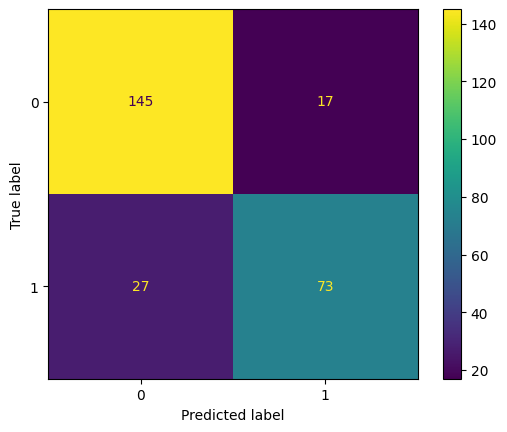

In [50]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

Finally, we plot the confusion matrix. The confusion matrix provides a visual breakdown of our model's predictions into four distinct categories:

* True Positives (TP): Passengers the model correctly predicted as survivors.

* True Negatives (TN): Passengers the model correctly predicted as non-survivors.

* False Positives (FP) / Type I Error: Passengers the model incorrectly predicted as survivors.

* False Negatives (FN) / Type II Error: Passengers the model incorrectly predicted as non-survivors.

Analyzing this matrix helps us understand exactly where the model is making mistakes—for example, whether it tends to be overly optimistic about survival chances (high FP) or too pessimistic (high FN).